In [1]:
!git clone https://github.com/WollyMonjac/Tiny-2.1.git
%cd /content/Tiny-2.1/training

Cloning into 'Tiny-2.1'...
remote: Enumerating objects: 59, done.
remote: Counting objects: 100% (59/59), done.
remote: Compressing objects: 100% (59/59), done.
remote: Total 59 (delta 4), reused 52 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (59/59), 1.83 MiB | 28.79 MiB/s, done.
Resolving deltas: 100% (4/4), done.
/content/Tiny-2.1/training


In [2]:
import math, struct
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import train2

print("PyTorch version:", torch.__version__)

def load_v2_bin(path):
    """Load a version-2 ('TNY2') 8-bit weight file into train2.Model."""
    b = open(path, "rb").read()
    assert b[:4] == b"TNY2", "Expected a TNY2 weight file"
    D, L, H, HID = struct.unpack_from("<4h", b, 4)
    off = [12]

    def table(r, c):
        w = np.empty((r, c), dtype=np.float32)
        for i in range(r):
            s = struct.unpack_from("<f", b, off[0])[0]
            w[i] = np.frombuffer(b, np.int8, c, off[0] + 4).astype(np.float32) * s
            off[0] += 4 + c
        return torch.tensor(w)

    def gains():
        g = np.frombuffer(b, "<f4", D, off[0]).copy()
        off[0] += 4 * D
        return torch.tensor(g)

    m = train2.Model(train2.Cfg(D, L, H, HID))
    with torch.no_grad():
        m.emb.weight.copy_(table(train2.VOCAB, D))
        m.pos.weight.copy_(table(train2.CTX, D))
        for blk in m.blocks:
            blk.n1.g.copy_(gains())
            for lin in (blk.q, blk.k, blk.v, blk.o):
                lin.weight.copy_(table(D, D))
            blk.n2.g.copy_(gains())
            blk.f1.weight.copy_(table(HID, D))
            blk.f2.weight.copy_(table(D, HID))
        m.nf.g.copy_(gains())
    assert off[0] == len(b), "size mismatch"
    return m

PyTorch version: 2.14.1+cpu


In [3]:
model = load_v2_bin("/content/Tiny-2.1/dos/TINY.BIN")
model.eval()

questions = [
    "what is 2+2?",
    "what is the capital of france?",
    "spell cat",
    "what is the capital of mars?",
]
answers = train2.answer_many(model, questions)
for q, a in answers.items():
    print(f"Q: {q}\nA: {a}\n")

print(model)
print("\nTotal trainable parameters:", f"{sum(p.numel() for p in model.parameters()):,}")

Q: what is 2+2?
A: The answer is 4.

Q: what is the capital of france?
A: The capital of France is Paris.

Q: spell cat
A: C-A-T.

Q: what is the capital of mars?
A: The capital is Majuro.

Model(
  (emb): Embedding(97, 96)
  (pos): Embedding(128, 96)
  (blocks): ModuleList(
    (0-3): 4 x Block(
      (n1): Norm()
      (n2): Norm()
      (q): Linear(in_features=96, out_features=96, bias=False)
      (k): Linear(in_features=96, out_features=96, bias=False)
      (v): Linear(in_features=96, out_features=96, bias=False)
      (o): Linear(in_features=96, out_features=96, bias=False)
      (f1): Linear(in_features=96, out_features=256, bias=False)
      (f2): Linear(in_features=256, out_features=96, bias=False)
    )
  )
  (nf): Norm()
)

Total trainable parameters: 366,528


In [4]:
# Tiny-2.1 character rule (from train2.py):
#   0      -> padding
#   1      -> newline '\n'
#   2..96  -> ASCII(c) - 30

word = "cat"
word_ids = train2.encode(word)
print("Word:", word, "-> IDs:", word_ids, "-> Decoded:", repr(train2.decode(word_ids)))

q, a = "2+2?", "4"
full_text = q + "\n" + a + "\n"
ids = train2.encode(full_text)

# Loss mask: 0 for question + first '\n', 1 for answer + final '\n'
mask = [0] * (len(q) + 1) + [1] * (len(ids) - len(q) - 1)

inputs_x  = ids[:-1]
targets_y = ids[1:]
loss_mask = mask[1:]

print("\nAligned training table for '2+2?\\n4\\n':")
for pos in range(len(inputs_x)):
    in_c  = repr(train2.decode([inputs_x[pos]]))[1:-1]
    tgt_c = repr(train2.decode([targets_y[pos]]))[1:-1]
    print(f"  pos {pos}: input={in_c:>3} (ID {inputs_x[pos]:2d}) -> target={tgt_c:>3} (ID {targets_y[pos]:2d}) | mask={loss_mask[pos]}")

Word: cat -> IDs: [69, 67, 86] -> Decoded: 'cat'

Aligned training table for '2+2?\n4\n':
  pos 0: input=  2 (ID 20) -> target=  + (ID 13) | mask=0
  pos 1: input=  + (ID 13) -> target=  2 (ID 20) | mask=0
  pos 2: input=  2 (ID 20) -> target=  ? (ID 33) | mask=0
  pos 3: input=  ? (ID 33) -> target= \n (ID  1) | mask=0
  pos 4: input= \n (ID  1) -> target=  4 (ID 22) | mask=1
  pos 5: input=  4 (ID 22) -> target= \n (ID  1) | mask=1


In [5]:
q, a = "capital of france?", "paris"
ids = train2.encode(q + "\n" + a + "\n")
mask = [0] * (len(q) + 1) + [1] * (len(ids) - len(q) - 1)

inputs_x, targets_y, loss_mask = ids[:-1], ids[1:], mask[1:]
print("Total length T:", len(ids))
print("Graded answer tokens:", sum(loss_mask))
print("Ignored question tokens:", len(loss_mask) - sum(loss_mask))
print("Graded targets:", repr(train2.decode([y for y, m in zip(targets_y, loss_mask) if m == 1])))

Total length T: 25
Graded answer tokens: 6
Ignored question tokens: 18
Graded targets: 'paris\n'


In [6]:
# Toy embedding table: row 0 = '2', row 1 = '+', row 2 = '?'
emb_small = torch.tensor([
    [1.0, 0.0],  # '2'
    [0.0, 1.0],  # '+'
    [0.3, 0.7],  # '?'
])

# Toy position table for positions 0, 1, 2, 3
pos_small = torch.tensor([
    [ 0.1,  0.2],  # pos 0
    [ 0.2, -0.1],  # pos 1
    [ 0.4, -0.1],  # pos 2
    [-0.2,  0.3],  # pos 3
])

# Token indices into emb_small for "2+2?" -> ['2', '+', '2', '?']
toy_ids = torch.tensor([0, 1, 0, 2], dtype=torch.long)

tok_vecs = emb_small[toy_ids]              # shape: (4, 2)
pos_vecs = pos_small[torch.arange(4)]      # shape: (4, 2)
X_small = tok_vecs + pos_vecs              # shape: (4, 2)

print("Token vectors ONLY (row 0 and row 2 are identical):\n", tok_vecs.numpy())
print("Position vectors:\n", pos_vecs.numpy())
print("Combined X = tok + pos (now row 0 and row 2 differ!):\n", np.round(X_small.numpy(), 2))

Token vectors ONLY (row 0 and row 2 are identical):
 [[1.  0. ]
 [0.  1. ]
 [1.  0. ]
 [0.3 0.7]]
Position vectors:
 [[ 0.1  0.2]
 [ 0.2 -0.1]
 [ 0.4 -0.1]
 [-0.2  0.3]]
Combined X = tok + pos (now row 0 and row 2 differ!):
 [[ 1.1  0.2]
 [ 0.2  0.9]
 [ 1.4 -0.1]
 [ 0.1  1. ]]


In [7]:
ids_22 = torch.tensor([train2.encode("2+2?\n4\n")], dtype=torch.long)  # shape: (1, 7)
T = ids_22.shape[1]

with torch.no_grad():
    tok_96 = model.emb(ids_22)                # shape: (1, 7, 96)
    pos_96 = model.pos(torch.arange(T))       # shape: (7, 96)
    X_96 = tok_96 + pos_96                    # broadcasts (7, 96) -> (1, 7, 96)

print("tok_96 shape:", tuple(tok_96.shape))
print("pos_96 shape:", tuple(pos_96.shape))
print("X_96 shape  :", tuple(X_96.shape))
print("First 5 values of '2' at pos 0:", np.round(X_96[0, 0, :5].numpy(), 3))
print("First 5 values of '2' at pos 2:", np.round(X_96[0, 2, :5].numpy(), 3))

tok_96 shape: (1, 7, 96)
pos_96 shape: (7, 96)
X_96 shape  : (1, 7, 96)
First 5 values of '2' at pos 0: [-0.7   -0.86  -0.508 -0.37  -0.515]
First 5 values of '2' at pos 2: [-0.369 -0.194 -0.178  0.169 -0.466]


In [8]:
id_12 = torch.tensor([train2.encode("12")], dtype=torch.long)
id_21 = torch.tensor([train2.encode("21")], dtype=torch.long)

with torch.no_grad():
    tok_12 = model.emb(id_12)
    tok_21 = model.emb(id_21)
    diff_no_pos = (tok_12[0, 1] - tok_21[0, 0]).abs().max().item()
    print("Max absolute difference for '2' WITHOUT pos:", diff_no_pos)

    pos_2 = model.pos(torch.arange(2))
    x_12 = tok_12 + pos_2
    x_21 = tok_21 + pos_2
    diff_with_pos = (x_12[0, 1] - x_21[0, 0]).abs().max().item()
    print("Max absolute difference for '2' WITH pos   :", diff_with_pos)

Max absolute difference for '2' WITHOUT pos: 0.0
Max absolute difference for '2' WITH pos   : 1.8126534223556519


In [9]:
# 3 toy tokens in 2D: x0 = [1, 0], x1 = [1, 1], x2 = [0, 1]
X_tiny = torch.tensor([
    [1.0, 0.0],  # token 0
    [1.0, 1.0],  # token 1
    [0.0, 1.0],  # token 2
])

# 1. Pairwise dot products: X @ X^T -> (3, 3)
scores_tiny = X_tiny @ X_tiny.T
print("Raw dot-product scores (3x3):\n", scores_tiny.numpy())

# 2. Softmax across columns (dim=-1) so each row sums to 1.0
weights_tiny = F.softmax(scores_tiny, dim=-1)
print("\nSoftmax attention weights (3x3):\n", np.round(weights_tiny.numpy(), 3))
print("Row sums:", weights_tiny.sum(dim=-1).numpy())

# 3. Context vectors = Weights @ X -> (3, 2)
context_tiny = weights_tiny @ X_tiny
print("\nContext vectors (3x2):\n", np.round(context_tiny.numpy(), 3))

Raw dot-product scores (3x3):
 [[1. 1. 0.]
 [1. 2. 1.]
 [0. 1. 1.]]

Softmax attention weights (3x3):
 [[0.422 0.422 0.155]
 [0.212 0.576 0.212]
 [0.155 0.422 0.422]]
Row sums: [1.        1.0000001 1.       ]

Context vectors (3x2):
 [[0.845 0.578]
 [0.788 0.788]
 [0.578 0.845]]


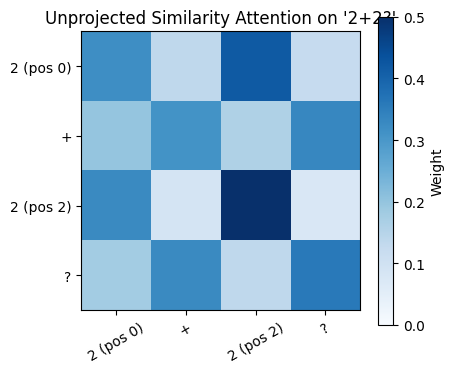

In [10]:
scores_4 = X_small @ X_small.T
weights_4 = F.softmax(scores_4, dim=-1)

labels_4 = ["2 (pos 0)", "+", "2 (pos 2)", "?"]
plt.figure(figsize=(4.5, 4))
plt.imshow(weights_4.numpy(), cmap="Blues", vmin=0.0, vmax=0.5)
plt.xticks(range(4), labels_4, rotation=30)
plt.yticks(range(4), labels_4)
plt.title("Unprojected Similarity Attention on '2+2?'")
plt.colorbar(label="Weight")
plt.show()

In [11]:
X_mat = X_96[0]                                # (7, 96)
sc_unweighted = X_mat @ X_mat.T                # (7, 7)
w_unweighted = F.softmax(sc_unweighted, dim=-1)

chars_7 = [repr(c)[1:-1] for c in "2+2?\n4\n"]
print("Tokens:", chars_7)
print("Row 4 ('\\n') weights across sequence:", np.round(w_unweighted[4].numpy(), 3))

Tokens: ['2', '+', '2', '?', '\\n', '4', '\\n']
Row 4 ('\n') weights across sequence: [0.    0.001 0.001 0.001 0.661 0.001 0.336]


In [12]:
# 1. Small 2D Q, K, V projections on X_tiny (3x2) from Part 4A
Wq_small = torch.tensor([[1.0, 0.0], [0.0, 0.5]])
Wk_small = torch.tensor([[0.0, 1.0], [1.0, 0.0]])
Wv_small = torch.tensor([[1.0, 1.0], [0.0, 1.0]])

Q_sm = X_tiny @ Wq_small.T
K_sm = X_tiny @ Wk_small.T
V_sm = X_tiny @ Wv_small.T

# 2. Scaled dot-product (d_k = 2)
dk = 2.0
scores_sm = (Q_sm @ K_sm.T) / math.sqrt(dk)
print("Scaled scores (3x3):\n", np.round(scores_sm.numpy(), 3))

# 3. Causal mask: 1 on/below diagonal, 0 above diagonal
mask_3 = torch.tril(torch.ones(3, 3))
print("\nLower-triangular causal mask:\n", mask_3.numpy().astype(int))

masked_scores_sm = scores_sm.masked_fill(mask_3 == 0, float("-inf"))
attn_sm = F.softmax(masked_scores_sm, dim=-1)
print("\nMasked attention weights (upper triangle = 0.0):\n", np.round(attn_sm.numpy(), 3))

# 4. Softmax scaling experiment
print("\nSoftmax on moderate scores [1.0, 2.0]:", np.round(F.softmax(torch.tensor([1.0, 2.0]), dim=0).numpy(), 3))
print("Softmax on large scores   [10.0, 20.0]:", np.round(F.softmax(torch.tensor([10.0, 20.0]), dim=0).numpy(), 5))

Scaled scores (3x3):
 [[0.    0.707 0.707]
 [0.354 1.061 0.707]
 [0.354 0.354 0.   ]]

Lower-triangular causal mask:
 [[1 0 0]
 [1 1 0]
 [1 1 1]]

Masked attention weights (upper triangle = 0.0):
 [[1.   0.   0.  ]
 [0.33 0.67 0.  ]
 [0.37 0.37 0.26]]

Softmax on moderate scores [1.0, 2.0]: [0.269 0.731]
Softmax on large scores   [10.0, 20.0]: [5.0000e-05 9.9995e-01]


In [13]:
blk = model.blocks[0]
with torch.no_grad():
    h = blk.n1(X_96)  # RMSNorm before attention -> shape (1, 7, 96)
    Q_96 = blk.q(h)
    K_96 = blk.k(h)
    V_96 = blk.v(h)

print("Q_96, K_96, V_96 shapes:", tuple(Q_96.shape), tuple(K_96.shape), tuple(V_96.shape))
print("Weight matrix shape of blk.q.weight:", tuple(blk.q.weight.shape))  # (96, 96)

Q_96, K_96, V_96 shapes: (1, 7, 96) (1, 7, 96) (1, 7, 96)
Weight matrix shape of blk.q.weight: (96, 96)


In [14]:
q_h0 = Q_96[:, :, :24]  # (1, 7, 24)
k_h0 = K_96[:, :, :24]  # (1, 7, 24)

sc_h0 = (q_h0 @ k_h0.transpose(-2, -1)) / math.sqrt(24)
mask_7 = torch.tril(torch.ones(7, 7))

w_masked   = F.softmax(sc_h0.masked_fill(mask_7 == 0, float("-inf")), dim=-1)
w_unmasked = F.softmax(sc_h0, dim=-1)

chars_7 = [repr(c)[1:-1] for c in "2+2?\n4\n"]
print("Tokens:", chars_7)
print("Row 4 ('\\n') WITH causal mask   :", np.round(w_masked[0, 4].numpy(), 3))
print("Row 4 ('\\n') WITHOUT causal mask:", np.round(w_unmasked[0, 4].numpy(), 3))

Tokens: ['2', '+', '2', '?', '\\n', '4', '\\n']
Row 4 ('\n') WITH causal mask   : [0.301 0.012 0.681 0.003 0.002 0.    0.   ]
Row 4 ('\n') WITHOUT causal mask: [0.161 0.006 0.364 0.002 0.001 0.465 0.001]


In [15]:
# 1 sequence, 3 tokens, 4 features per token
tiny_q = torch.tensor([[
    [10.0, 11.0, 12.0, 13.0],
    [20.0, 21.0, 22.0, 23.0],
    [30.0, 31.0, 32.0, 33.0],
]])  # shape: (1, 3, 4)

B_s, T_s, D_s, H_s = 1, 3, 4, 2
Dh_s = D_s // H_s  # 2

# 1. Reshape last dimension D -> (H=2, Dh=2): shape -> (1, 3, 2, 2)
reshaped = tiny_q.view(B_s, T_s, H_s, Dh_s)

# 2. Swap sequence dimension (1) and head dimension (2): shape -> (1, 2, 3, 2)
split_q = reshaped.transpose(1, 2)

print("Original shape (B, T, D):", tuple(tiny_q.shape))
print("Split shape (B, H, T, Dh):", tuple(split_q.shape))
print("Head 0 across all 3 tokens:\n", split_q[0, 0].numpy())
print("Head 1 across all 3 tokens:\n", split_q[0, 1].numpy())

# 3. Concatenate heads back and verify equality
merged = split_q.transpose(1, 2).reshape(B_s, T_s, D_s)
print("Merged tensor matches original:", torch.equal(merged, tiny_q))

Original shape (B, T, D): (1, 3, 4)
Split shape (B, H, T, Dh): (1, 2, 3, 2)
Head 0 across all 3 tokens:
 [[10. 11.]
 [20. 21.]
 [30. 31.]]
Head 1 across all 3 tokens:
 [[12. 13.]
 [22. 23.]
 [32. 33.]]
Merged tensor matches original: True


Maximum absolute difference vs F.scaled_dot_product_attention: 1.430511474609375e-06


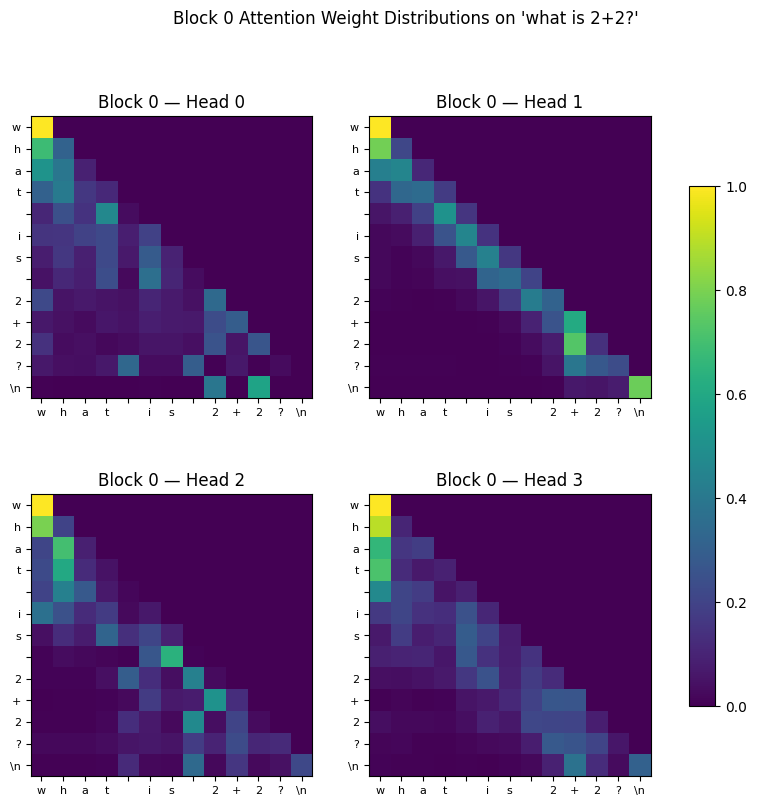

In [16]:
prompt = "what is 2+2?\n"
p_ids = torch.tensor([train2.encode(prompt)], dtype=torch.long)
T_p = p_ids.shape[1]
chars_p = [repr(c)[1:-1] for c in prompt]

with torch.no_grad():
    x_p = model.emb(p_ids) + model.pos(torch.arange(T_p))
    blk = model.blocks[0]
    h_p = blk.n1(x_p)

    # Tensor splitting helper matching train2.py
    sp = lambda t: t.view(1, T_p, 4, 24).transpose(1, 2)
    qh, kh, vh = sp(blk.q(h_p)), sp(blk.k(h_p)), sp(blk.v(h_p))

    # Manual multi-head causal attention calculation
    scores_p = (qh @ kh.transpose(-2, -1)) / math.sqrt(24)
    mask_p = torch.tril(torch.ones(T_p, T_p))
    attn_p = F.softmax(scores_p.masked_fill(mask_p == 0, float("-inf")), dim=-1)  # (1, 4, T_p, T_p)

    context_p = attn_p @ vh                                                        # (1, 4, T_p, 24)
    context_merged = context_p.transpose(1, 2).reshape(1, T_p, 96)                 # (1, T_p, 96)
    attn_output = blk.o(context_merged)                                            # (1, T_p, 96)

    # Cross-check against optimized PyTorch operator
    fast_a = F.scaled_dot_product_attention(qh, kh, vh, is_causal=True)
    fast_out = blk.o(fast_a.transpose(1, 2).reshape(1, T_p, 96))
    max_discrepancy = (attn_output - fast_out).abs().max().item()
    print("Maximum absolute difference vs F.scaled_dot_product_attention:", max_discrepancy)

# Plot attention distributions across all 4 heads
fig, axes = plt.subplots(2, 2, figsize=(10, 9))
for head_idx, ax in enumerate(axes.flat):
    im = ax.imshow(attn_p[0, head_idx].numpy(), cmap="viridis", vmin=0.0)
    ax.set_title(f"Block 0 — Head {head_idx}")
    ax.set_xticks(range(len(chars_p))); ax.set_xticklabels(chars_p, fontsize=8)
    ax.set_yticks(range(len(chars_p))); ax.set_yticklabels(chars_p, fontsize=8)
fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.75)
plt.suptitle(f"Block 0 Attention Weight Distributions on '{prompt.strip()}'")
plt.show()

In [17]:
@torch.no_grad()
def inspect_last_token_heads(prompt_str):
    ids = torch.tensor([train2.encode(prompt_str)], dtype=torch.long)
    T_len = ids.shape[1]
    ch = [repr(c)[1:-1] for c in prompt_str]
    x = model.emb(ids) + model.pos(torch.arange(T_len))
    blk = model.blocks[0]
    h = blk.n1(x)
    sp_fn = lambda t: t.view(1, T_len, 4, 24).transpose(1, 2)
    q, k = sp_fn(blk.q(h)), sp_fn(blk.k(h))
    sc = (q @ k.transpose(-2, -1)) / math.sqrt(24)
    mk = torch.tril(torch.ones(T_len, T_len))
    at = F.softmax(sc.masked_fill(mk == 0, float("-inf")), dim=-1)

    print(f"\n=== Prompt: {repr(prompt_str)} ===")
    for h_i in range(4):
        w = at[0, h_i, -1].numpy()
        top3 = np.argsort(w)[::-1][:3]
        desc = ", ".join(f"pos {i} ('{ch[i]}'): {w[i]:.2f}" for i in top3)
        print(f"  Head {h_i}: {desc}")

inspect_last_token_heads("what is 2+2?\n")
inspect_last_token_heads("what is the capital of france?\n")


=== Prompt: 'what is 2+2?\n' ===
  Head 0: pos 10 ('2'): 0.58, pos 8 ('2'): 0.39, pos 0 ('w'): 0.01
  Head 1: pos 12 ('\n'): 0.78, pos 11 ('?'): 0.08, pos 9 ('+'): 0.06
  Head 2: pos 7 (' '): 0.34, pos 12 ('\n'): 0.22, pos 9 ('+'): 0.16
  Head 3: pos 9 ('+'): 0.38, pos 12 ('\n'): 0.31, pos 10 ('2'): 0.13

=== Prompt: 'what is the capital of france?\n' ===
  Head 0: pos 14 ('p'): 0.13, pos 23 ('f'): 0.12, pos 21 ('f'): 0.09
  Head 1: pos 30 ('\n'): 0.78, pos 29 ('?'): 0.09, pos 28 ('e'): 0.05
  Head 2: pos 30 ('\n'): 0.19, pos 26 ('n'): 0.12, pos 27 ('c'): 0.12
  Head 3: pos 30 ('\n'): 0.47, pos 27 ('c'): 0.14, pos 28 ('e'): 0.09
